# **INF01017 - Aprendizado de Máquina - INF/UFRGS**
#### *Profa. Mariana Recamonde Mendoza*

## Trabalho Prático Final - Parte 1 (T1): Caracterização do problema e *spot-checking* de algoritmos

### Detector de Ataques Cardíacos

**Integrantes:** Gabriel Pieruccini Knopp, Vitor Santana Feijó

**Dataset:** [Health care: Data set on Heart attack possibility (Kaggle)](https://www.kaggle.com/datasets/nareshbhat/health-care-data-set-on-heart-attack-possibility)

---

**Roteiro do notebook**

1. Definição do problema
2. Configuração do ambiente
3. Carregamento dos dados
4. Análise exploratória dos dados (EDA)
5. Pré-processamento dos dados
6. Definição da abordagem, dos algoritmos e da estratégia de avaliação
7. *Spot-checking* de algoritmos
8. Sumarização dos resultados
9. Conclusão: seleção dos modelos para o T2

# 1. Definição do problema

Nosso trabalho tem como objetivo desenvolver um modelo baseado em Aprendizado de Máquina para **prever a tendência de ataque cardíaco de um paciente**, representada pela **presença de doença cardíaca** (estreitamento superior a 50% do diâmetro de uma artéria coronária principal), a partir de um conjunto de características clínicas e de exames (idade, sexo, tipo de dor no peito, pressão arterial, colesterol, resultados de eletrocardiograma e de teste de esforço, entre outros).

Para tanto, utilizamos o conjunto de dados *Health care: Data set on Heart attack possibility*, disponível no [Kaggle](https://www.kaggle.com/datasets/nareshbhat/health-care-data-set-on-heart-attack-possibility). Ele é uma versão recodificada da base *Cleveland* do [UCI Heart Disease](https://archive.ics.uci.edu/dataset/45/heart+disease), com 303 registros e 13 atributos preditivos.

**Pergunta de pesquisa:** *é possível distinguir, com bom desempenho, pacientes com e sem doença cardíaca usando apenas esses 13 atributos clínicos? Quais famílias de algoritmos são mais promissoras para essa tarefa?*

Como o atributo-alvo (`target`) é **binário**, trata-se de um problema de **classificação binária**.

### Dicionário de dados

O significado dos códigos abaixo foi **verificado na Seção 4.3**, comparando cada registro com a base original da UCI, destacando-se o fato de que em alguns atributos ele difere da descrição publicada no Kaggle. Portanto, decidimos manter o que interpretamos como correto: usamos as definições do registro da base original da UCI.

| Atributo | Descrição | Natureza | Códigos |
|---|---|---|---|
| `age` | Idade (anos) | Numérico | - |
| `sex` | Sexo | Binário | 0 = feminino; 1 = masculino |
| `cp` | Tipo de dor no peito | Categórico nominal | 0 = assintomática; 1 = angina atípica; 2 = dor não anginosa; 3 = angina típica |
| `trestbps` | Pressão arterial em repouso (mm Hg) | Numérico | - |
| `chol` | Colesterol sérico (mg/dl) | Numérico | - |
| `fbs` | Glicemia em jejum > 120 mg/dl | Binário | 0 = não; 1 = sim |
| `restecg` | Eletrocardiograma em repouso | Categórico nominal | 0 = hipertrofia ventricular esquerda; 1 = normal; 2 = anormalidade de onda ST-T |
| `thalach` | Frequência cardíaca máxima atingida (bpm) | Numérico | - |
| `exang` | Angina induzida por exercício | Binário | 0 = não; 1 = sim |
| `oldpeak` | Depressão do segmento ST induzida por exercício em relação ao repouso | Numérico | ≥ 0 |
| `slope` | Inclinação do segmento ST no pico do exercício | Categórico nominal | 0 = descendente; 1 = plana; 2 = ascendente |
| `ca` | Número de vasos principais coloridos por fluoroscopia | Discreto ordinal | 0 a 3 |
| `thal` | Cintilografia com tálio | Categórico nominal | 1 = defeito fixo; 2 = normal; 3 = defeito reversível |
| `target` | Diagnóstico de doença cardíaca | **Alvo** (binário) | 0 = com doença; 1 = sem doença (recodificado na Seção 5.1) |

Destacamos que, embora **todos** os atributos estejam armazenados como números, vários deles (`cp`, `restecg`, `slope`, `thal`) são **códigos de categorias**, sem relação de ordem ou distância entre os valores, o que mais tarde exigirá a aplicação do One-hot encoding.

# 2. Configuração do ambiente

Bibliotecas principais: `pandas`, `numpy`, `matplotlib`, `seaborn` e `scikit-learn` (todas já disponíveis no Google Colab).

In [1]:
## Carregando as bibliotecas básicas necessárias
# A primeira linha é incluída para gerar os gráficos logo abaixo dos comandos de plot
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

import warnings
warnings.filterwarnings("ignore")

## Semente única para todos os processos aleatórios (reprodutibilidade dos experimentos)
RANDOM_STATE = 42

## Configuração visual dos gráficos
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "grid.color": "#e1e0d9",
})

COR_PRINCIPAL = "#2a78d6"              # gráficos de uma única série
COR_ALERTA = "#d03b3b"                 # destaca o que exige atenção no pré-processamento
CORES_CLASSE = {0: "#2a78d6", 1: "#eb6834"}
NOMES_CLASSE = {0: "0 - com doença", 1: "1 - sem doença"}   # codificação original do arquivo

In [2]:
def rotular_barras(ax, fmt="{:.0f}", sufixos=None, horizontal=False):
    """Escreve o valor de cada barra ao lado/acima dela (rótulos seletivos, sem poluir o gráfico)."""
    for i, barra in enumerate(ax.patches):
        valor = barra.get_width() if horizontal else barra.get_height()
        if np.isnan(valor):
            continue
        texto = fmt.format(valor) + (sufixos[i] if sufixos is not None else "")
        if horizontal:
            ax.annotate(texto, (valor, barra.get_y() + barra.get_height() / 2),
                        xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
        else:
            ax.annotate(texto, (barra.get_x() + barra.get_width() / 2, valor),
                        xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)


def cores_por_alerta(valores, condicao):
    """Retorna uma lista de cores: vermelho onde a condição é verdadeira, azul nos demais."""
    return [COR_ALERTA if c else COR_PRINCIPAL for c in condicao(np.asarray(valores))]


def legenda_alerta(ax, texto_alerta, texto_ok="sem problema", loc="lower right"):
    """Legenda das cores de alerta; `ax` pode ser um eixo ou a figura inteira."""
    from matplotlib.patches import Patch
    ax.legend(handles=[Patch(color=COR_ALERTA, label=texto_alerta),
                       Patch(color=COR_PRINCIPAL, label=texto_ok)], loc=loc, fontsize=9)

# 3. Carregamento dos dados

O arquivo `heart.csv` (idêntico ao disponibilizado no Kaggle) está versionado no repositório do grupo no GitHub. Assim, o notebook funciona tanto localmente quanto no Google Colab, sem necessidade de upload manual ou de credenciais do Kaggle.

In [3]:
## Carregando os dados
# encoding="utf-8-sig" remove o BOM presente no início do arquivo (senão a 1ª coluna viria como "﻿age")
URL_DADOS = "https://raw.githubusercontent.com/vitorsfeijo/Trabalho_ML/main/heart.csv"

try:
    df_original = pd.read_csv("heart.csv", encoding="utf-8-sig")   # execução local
except FileNotFoundError:
    df_original = pd.read_csv(URL_DADOS, encoding="utf-8-sig")     # execução no Google Colab

# Visualização inicial
df_original.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


# 4. Análise exploratória dos dados (EDA)

A EDA que realizamos aqui é **descritiva** e usa o conjunto completo, tal como foi recebido. Ela não ajusta nenhuma transformação que será usada pelos modelos: todas as etapas que **aprendem parâmetros** dos dados (imputação, codificação e padronização) são definidas na Seção 5 e ajustadas **somente nos dados de treino** de cada *fold*, o que evita vazamento de informação (*data leakage*). Nos gráficos de diagnóstico, **vermelho** indica o que requer atenção no pré-processamento.

## 4.1. Visão geral: quantidade e tipos de atributos

In [4]:
print("===== VISÃO GERAL DO DATASET =====")
print(f"Número de instâncias: {df_original.shape[0]}")
print(f"Número de atributos (incluindo o alvo): {df_original.shape[1]}")
print()
df_original.info()

===== VISÃO GERAL DO DATASET =====
Número de instâncias: 303
Número de atributos (incluindo o alvo): 14

<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [5]:
## Agrupamento dos atributos segundo sua natureza (dicionário de dados da Seção 1).
## Atenção: todos estão armazenados como inteiros/reais, mas nem todos são quantitativos.
ALVO = "target"
ATR_CONTINUOS = ["age", "trestbps", "chol", "thalach", "oldpeak"]   # numéricos
ATR_BINARIOS = ["sex", "fbs", "exang"]
ATR_NOMINAIS = ["cp", "restecg", "slope", "thal"]                    # categorias codificadas como inteiros
ATR_ORDINAIS = ["ca"]                                                # contagem de vasos (0 a 3)
ATR_DISCRETOS = ATR_BINARIOS + ATR_NOMINAIS + ATR_ORDINAIS

natureza = {**{c: "numérico" for c in ATR_CONTINUOS},
            **{c: "binário" for c in ATR_BINARIOS},
            **{c: "categórico nominal" for c in ATR_NOMINAIS},
            **{c: "discreto ordinal" for c in ATR_ORDINAIS},
            ALVO: "alvo (binário)"}

resumo_tipos = pd.DataFrame({
    "tipo armazenado": df_original.dtypes.astype(str),
    "natureza": pd.Series(natureza),
    "valores distintos": df_original.nunique(),
    "mínimo": df_original.min(),
    "máximo": df_original.max(),
})
display(resumo_tipos)
print(resumo_tipos["natureza"].value_counts().to_string())

,tipo armazenado,natureza,valores distintos,mínimo,máximo
age,int64,numérico,41,29.0,77.0
ca,int64,discreto ordinal,5,0.0,4.0
chol,int64,numérico,152,126.0,564.0
cp,int64,categórico nominal,4,0.0,3.0
exang,int64,binário,2,0.0,1.0
fbs,int64,binário,2,0.0,1.0
oldpeak,float64,numérico,40,0.0,6.2
restecg,int64,categórico nominal,3,0.0,2.0
sex,int64,binário,2,0.0,1.0
slope,int64,categórico nominal,3,0.0,2.0


natureza
numérico              5
categórico nominal    4
binário               3
discreto ordinal      1
alvo (binário)        1


In [6]:
## Estatísticas descritivas de todos os atributos
df_original.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.37,9.08,29.0,47.5,55.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,0.97,1.03,0.0,0.0,1.0,2.0,3.0
trestbps,303.0,131.62,17.54,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.26,51.83,126.0,211.0,240.0,274.5,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.53,0.53,0.0,0.0,1.0,1.0,2.0
thalach,303.0,149.65,22.91,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


**Observações/Resumo:**
- São **303 instâncias** e **13 atributos preditivos + 1 alvo**, todos armazenados como numéricos (`int64`, exceto `oldpeak`, que é `float64`).
- Apenas 5 atributos são de fato quantitativos contínuos (`age`, `trestbps`, `chol`, `thalach`, `oldpeak`); 3 são binários; `ca` é uma contagem; e 4 (`cp`, `restecg`, `slope`, `thal`) são **categorias nominais codificadas como inteiros**.
- As magnitudes são muito diferentes entre atributos (ex.: `chol` vai até centenas, `oldpeak` fica entre 0 e ~6) - indício de necessidade de normalização (Seção 5.6).
- Os valores máximos de `ca` (4) e o mínimo de `thal` (0) são prova da inconsistência do Dataset do Kaggle em relação à Database da UCI - entraremos em mais detalhes na Seção 4.3.

## 4.2. Valores faltantes e instâncias duplicadas

In [7]:
## Verifica se existem valores faltantes (missing)
print("Valores faltantes (NaN) por atributo:")
print(df_original.isnull().sum().to_string())
print(f"\nTotal de valores faltantes: {df_original.isnull().sum().sum()}")

## Verifica instâncias duplicadas (todas as colunas iguais)
n_duplicadas = df_original.duplicated().sum()
print(f"\nInstâncias duplicadas: {n_duplicadas}")
display(df_original[df_original.duplicated(keep=False)])

Valores faltantes (NaN) por atributo:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0

Total de valores faltantes: 0

Instâncias duplicadas: 1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1


Não há valores faltantes _explícitos_ (discutiremos melhor a seguir), mas existe **1 instância duplicada** (linhas 163 e 164 idênticas em todos os 14 atributos). Em uma base de 303 pacientes, acreditamos que isso é muito provavelmente um erro de registro, então trataremos ela posteriormente.

## 4.3. Consistência: valores fora do domínio esperado

A descrição do Kaggle informa `ca` como *"number of major vessels (0-3)"* e `thal` como *"0 = normal; 1 = fixed defect; 2 = reversable defect"*. Começamos comparando os valores observados com esses domínios.

In [8]:
## Distribuição dos valores dos atributos com códigos suspeitos
print("ca:  ", df_original["ca"].value_counts().sort_index().to_dict())
print("thal:", df_original["thal"].value_counts().sort_index().to_dict())

ca:   {0: 175, 1: 65, 2: 38, 3: 20, 4: 5}
thal: {0: 2, 1: 18, 2: 166, 3: 117}


Aqui, destacamos a nossa crença de que os valores de `thal` **não batem com a descrição do Kaggle**. Podemos observar que aparecem os códigos 1, 2 e **3** (este último em 117 pacientes), e o código 0 (que deveria representar "normal", segundo a descrição do Kaggle) aparece em apenas 2. Se a descrição estivesse correta, o código 3 - usado por mais de um terço da base - seria inválido, o que é implausível. Portanto, para resolver a dúvida com evidência, comparamos **cada registro** com a base original *Cleveland* da UCI, da qual esta versão deriva. 

A documentação oficial da UCI (`heart-disease.names`) define:

- *"thal: 3 = normal; 6 = fixed defect; 7 = reversable defect"*;
- *"ca: number of major vessels (0-3) colored by flourosopy"*;
- *"num: diagnosis of heart disease (angiographic disease status) - Value 0: < 50% diameter narrowing; Value 1: > 50% diameter narrowing"*, sendo que os estudos com a base distinguem *"presence (values 1,2,3,4) from absence (value 0)"*;
- valores ausentes são marcados com `?` no arquivo `processed.cleveland.data`.

Para comparar cada um, casamos cada registro Kaggle com um da UCI, e conseguimos fazer isso usando apenas 6 atributos (`age`, `sex`, `trestbps`, `chol`, `thalach`, `oldpeak`). Os demais 7 atributos e o alvo não participam do casamento e, portanto, podem ser usados somente para validá-lo (se os registros estiverem corretamente pareados, cada código do Kaggle deve corresponder a um único código da UCI).

In [9]:
## Base original (UCI Heart Disease - Cleveland, 303 registros), com "?" representando valores ausentes.
## Cópia fiel do arquivo da UCI (licença CC BY 4.0), versionada no repositório para não depender do servidor
## da UCI. Original: https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data
URL_UCI = "https://raw.githubusercontent.com/vitorsfeijo/Trabalho_ML/main/processed.cleveland.data"
colunas_uci = list(df_original.columns[:-1]) + ["num"]

try:
    df_uci = pd.read_csv("processed.cleveland.data", header=None, names=colunas_uci, na_values="?")
except FileNotFoundError:
    df_uci = pd.read_csv(URL_UCI, header=None, names=colunas_uci, na_values="?")
print("Valores ausentes ('?') na base da UCI:", df_uci.isnull().sum()[lambda s: s > 0].to_dict())

## Casamento registro a registro pelos atributos contínuos + sexo (combinação que identifica cada paciente)
chave = ["age", "sex", "trestbps", "chol", "thalach", "oldpeak"]
casados = (df_original.astype({c: float for c in chave}).reset_index(names="id_kaggle")
           .merge(df_uci.astype({c: float for c in chave}).reset_index(names="id_uci"),
                  on=chave, suffixes=("", "_uci")))
print(f"Registros do Kaggle encontrados na UCI: {casados['id_kaggle'].nunique()} de {len(df_original)} "
      f"(pares formados: {len(casados)}; nenhum registro casou com mais de um paciente)")

## Validação do casamento: cada código do Kaggle deve corresponder a UM único código da UCI
print("\nCódigo no Kaggle → código na UCI (atributos fora da chave de casamento):")
for col in ["cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]:
    uci_por_codigo = casados.groupby(col)[col + "_uci"].agg(lambda s: set(s.fillna(-1)))
    unico = all(len(v) == 1 for v in uci_por_codigo)
    mapa = {k: ("?" if v == {-1} else f"{next(iter(v)):g}") for k, v in uci_por_codigo.items()}
    print(f"  {col:8s} {mapa}   correspondência única: {unico}")

## Alvo do Kaggle × diagnóstico original da UCI
display(pd.crosstab(casados[ALVO], casados["num"].gt(0).map({False: "num = 0 (< 50%: sem doença)",
                                                             True: "num > 0 (> 50%: com doença)"}),
                    rownames=["target (Kaggle)"], colnames=["diagnóstico (UCI)"]))

## A duplicata: dois registros do Kaggle correspondem ao MESMO paciente da UCI
display(casados[casados.duplicated("id_uci", keep=False)][["id_kaggle", "id_uci"]])
print(f"Pacientes da UCI ausentes no Kaggle: {len(df_uci) - casados['id_uci'].nunique()}")

Valores ausentes ('?') na base da UCI: {'ca': 4, 'thal': 2}
Registros do Kaggle encontrados na UCI: 303 de 303 (pares formados: 303; nenhum registro casou com mais de um paciente)

Código no Kaggle → código na UCI (atributos fora da chave de casamento):
  cp       {0: '4', 1: '2', 2: '3', 3: '1'}   correspondência única: True
  fbs      {0: '0', 1: '1'}   correspondência única: True
  restecg  {0: '2', 1: '0', 2: '1'}   correspondência única: True
  exang    {0: '0', 1: '1'}   correspondência única: True
  slope    {0: '3', 1: '2', 2: '1'}   correspondência única: True
  ca       {0: '0', 1: '1', 2: '2', 3: '3', 4: '?'}   correspondência única: True
  thal     {0: '?', 1: '6', 2: '3', 3: '7'}   correspondência única: True


diagnóstico (UCI),num = 0 (< 50%: sem doença),num > 0 (> 50%: com doença)
target (Kaggle),,
0,0,138
1,165,0


,id_kaggle,id_uci
163,163,302
164,164,302


Pacientes da UCI ausentes no Kaggle: 1


**O que concluimos da verificação:** todos os 303 registros do Kaggle têm correspondente na UCI, e, em **todos** os 7 atributos fora da chave, cada código do Kaggle corresponde a exatamente um código original (o que seria praticamente impossível com um pareamento errado). Portanto, olhando agora diretamente para o database da UCI, inferimos que:

| Atributo | Significado real dos códigos do Kaggle | Correção necessária? |
|---|---|---|
| `ca` | 0-3 = número de vasos (idênticos à UCI); **4 = valor ausente** (`?` na UCI) | **Sim**: `ca = 4` (4 pacientes + a duplicata) |
| `thal` | **0 = valor ausente** (`?` na UCI); 1 = defeito fixo; 2 = normal; 3 = defeito reversível | **Sim**: `thal = 0` (2 pacientes) |
| `cp`, `restecg`, `slope` | Códigos válidos, apenas **permutados** em relação à UCI (ver dicionário de dados) | Não |
| `target` | 1 = sem doença (`num = 0`); 0 = com doença (`num > 0`), sem nenhuma exceção | Recodificado na Seção 5.1 |

Conclusões:
- A descrição do `thal` publicada no Kaggle está **incorreta**: "normal" é o código 2 (166 pacientes), e o código 0 não é uma categoria, mas a marcação de **valor ausente**. O mesmo ocorre com `ca = 4`. Esses números coincidem exatamente com os valores ausentes da base original (4 em `ca` e 2 em `thal`). **Somente essas 6 instâncias precisam de correção** (Seção 5.4). Assim, nenhum outro atributo tem valores fora do domínio.
- A **duplicata** é um artefato da versão do Kaggle: um paciente da UCI foi copiado duas vezes, enquanto outro paciente original ficou de fora. Deixaremos o "esquecido" de fora, mas removeremos a duplicata (a fim de trabalhar somente com os dados do dataset do Kaggle).
- O alvo tem o sentido **oposto** ao da descrição do Kaggle ("1 = more chance of heart attack"): `target` é uma função exata do diagnóstico da UCI, com `target = 1` ⇔ estreitamento < 50% (**sem** doença). Os padrões clínicos da Seção 4.5 corroboram essa leitura. Contudo, **só realizaremos a correção desse fato na seção 5**, para mantermos a análise dos dados consistente até o final.

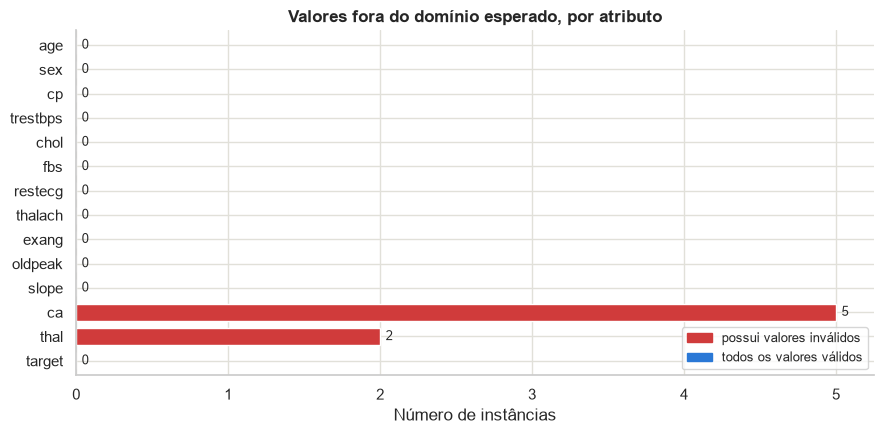

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
48,53,0,2,128,216,0,0,115,0,0.0,2,0,0,1
92,52,1,2,138,223,0,1,169,0,0.0,2,4,2,1
158,58,1,1,125,220,0,1,144,0,0.4,1,4,3,1
163,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
164,38,1,2,138,175,0,1,173,0,0.0,2,4,2,1
251,43,1,0,132,247,1,0,143,1,0.1,1,4,3,0
281,52,1,0,128,204,1,1,156,1,1.0,1,0,0,0


In [10]:
## Domínio esperado de cada atributo discreto (codificação real, verificada acima)
DOMINIO_ESPERADO = {
    "sex": {0, 1}, "fbs": {0, 1}, "exang": {0, 1},
    "cp": {0, 1, 2, 3}, "restecg": {0, 1, 2}, "slope": {0, 1, 2},
    "ca": {0, 1, 2, 3},     # número de vasos principais: 0 a 3
    "thal": {1, 2, 3},      # 0 marca valor ausente
    "target": {0, 1},
}
## Faixas plausíveis (amplas) para os atributos numéricos, apenas para detectar erros grosseiros
FAIXA_PLAUSIVEL = {
    "age": (18, 100), "trestbps": (70, 250), "chol": (100, 700),
    "thalach": (60, 220), "oldpeak": (0, 10),
}

fora_dominio = {}
for col, valores in DOMINIO_ESPERADO.items():
    fora_dominio[col] = (~df_original[col].isin(valores)).sum()
for col, (minimo, maximo) in FAIXA_PLAUSIVEL.items():
    fora_dominio[col] = (~df_original[col].between(minimo, maximo)).sum()

fora_dominio = pd.Series(fora_dominio)[df_original.columns]

fig, ax = plt.subplots(figsize=(9, 4.5))
fora_dominio.plot.barh(ax=ax, color=cores_por_alerta(fora_dominio, lambda v: v > 0), width=0.7)
rotular_barras(ax, horizontal=True)
ax.invert_yaxis()
ax.set_title("Valores fora do domínio esperado, por atributo")
ax.set_xlabel("Número de instâncias")
legenda_alerta(ax, "possui valores inválidos", "todos os valores válidos")
plt.tight_layout()
plt.show()

display(df_original[(df_original["ca"] == 4) | (df_original["thal"] == 0)])

## 4.4. Distribuição do atributo-alvo

        instâncias  proporção
target                       
0              138      0.455
1              165      0.545

Razão de desbalanceamento (classe majoritária / minoritária): 1.20


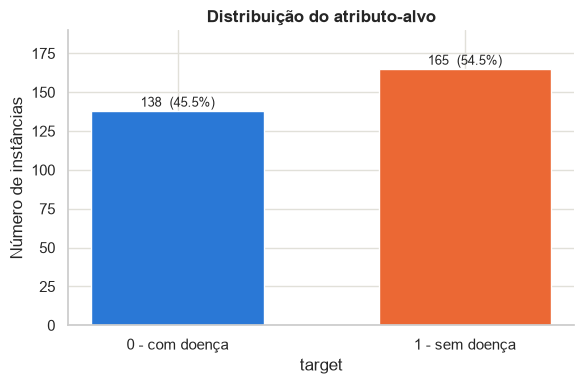

In [11]:
## Distribuição do atributo alvo
contagem_alvo = df_original[ALVO].value_counts().sort_index()
proporcao_alvo = df_original[ALVO].value_counts(normalize=True).sort_index()
print(pd.DataFrame({"instâncias": contagem_alvo, "proporção": proporcao_alvo.round(3)}))
print(f"\nRazão de desbalanceamento (classe majoritária / minoritária): "
      f"{contagem_alvo.max() / contagem_alvo.min():.2f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar([NOMES_CLASSE[c] for c in contagem_alvo.index], contagem_alvo.values,
       color=[CORES_CLASSE[c] for c in contagem_alvo.index], width=0.6)
rotular_barras(ax, sufixos=[f"  ({p:.1%})" for p in proporcao_alvo.values])
ax.set_title("Distribuição do atributo-alvo")
ax.set_xlabel("target")
ax.set_ylabel("Número de instâncias")
ax.set_ylim(0, contagem_alvo.max() * 1.15)
plt.tight_layout()
plt.show()

As classes estão **levemente desbalanceadas**: ~54% da classe 1 (sem doença) e ~46% da classe 0 (com doença), razão ≈ 1,2.

**Concluímos, assim, que não há necessidade de balanceamento de classes.** Entendemos que uma diferença tão pequena entre as classes não é suficiente para enviesar os classificadores em favor da classe majoritária, e técnicas de reamostragem (SMOTE, *undersampling*) criariam ou descartariam instâncias sem necessidade. A proporção das classes é preservada pela **estratificação** de todas as divisões (Seções 5.3 e 6.4), e a avaliação usa métricas focadas na classe de interesse além da acurácia (Seção 6.3).

## 4.5. Relação dos atributos com o alvo

### Atributos numéricos por classe

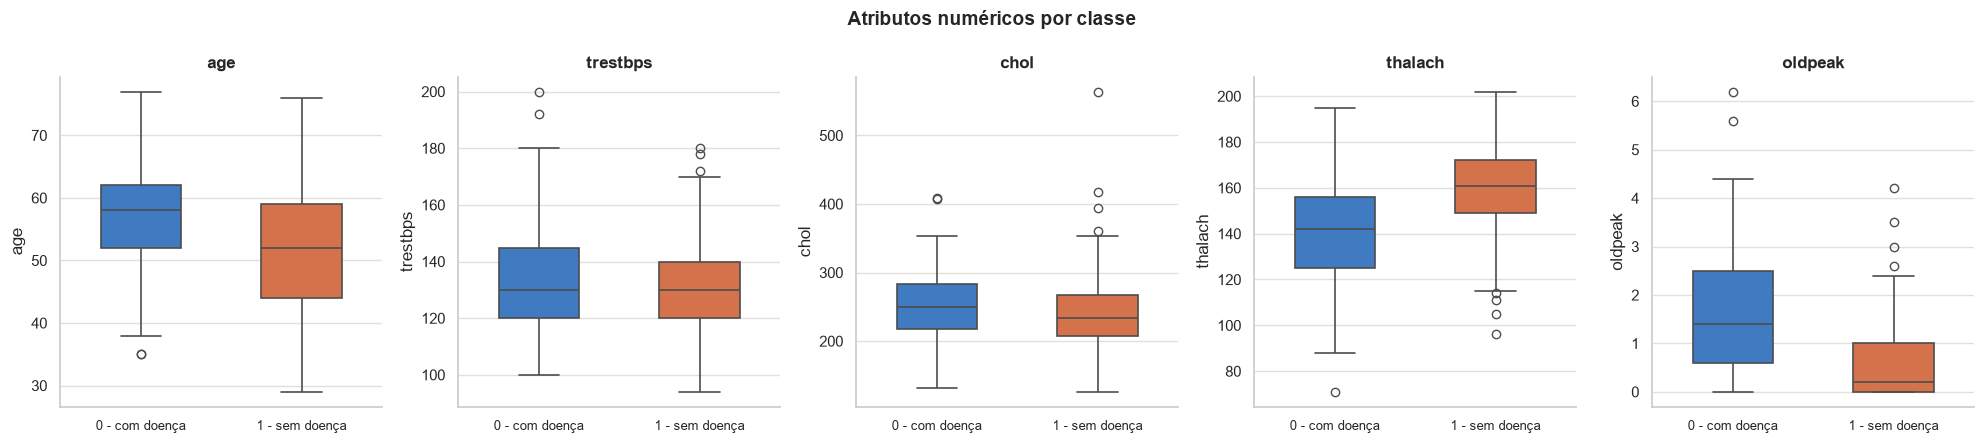

,age,trestbps,chol,thalach,oldpeak
target,,,,,
0 - com doença,56.6,134.4,251.09,139.10,1.59
1 - sem doença,52.5,129.3,242.23,158.47,0.58


In [12]:
## Boxplots de cada atributo numérico separados pela classe
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, ATR_CONTINUOS):
    sns.boxplot(data=df_original, x=ALVO, y=col, hue=ALVO, palette=CORES_CLASSE,
                legend=False, ax=ax, width=0.5, linewidth=1.2)
    ax.set_title(col)
    ax.set_xticks([0, 1], [NOMES_CLASSE[0], NOMES_CLASSE[1]], fontsize=9)
    ax.set_xlabel("")
fig.suptitle("Atributos numéricos por classe", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## Médias por classe
df_original.groupby(ALVO)[ATR_CONTINUOS].mean().round(2).rename(index=NOMES_CLASSE)

### Atributos discretos por classe

Cada barra mostra, para um valor do atributo, a proporção de pacientes em cada classe. O número de instâncias de cada valor (`n`) aparece no eixo - barras com `n` pequeno são pouco confiáveis. Os códigos de ausência (`ca = 4`, `thal = 0`) ainda aparecem aqui, pois são tratados apenas na Seção 5.

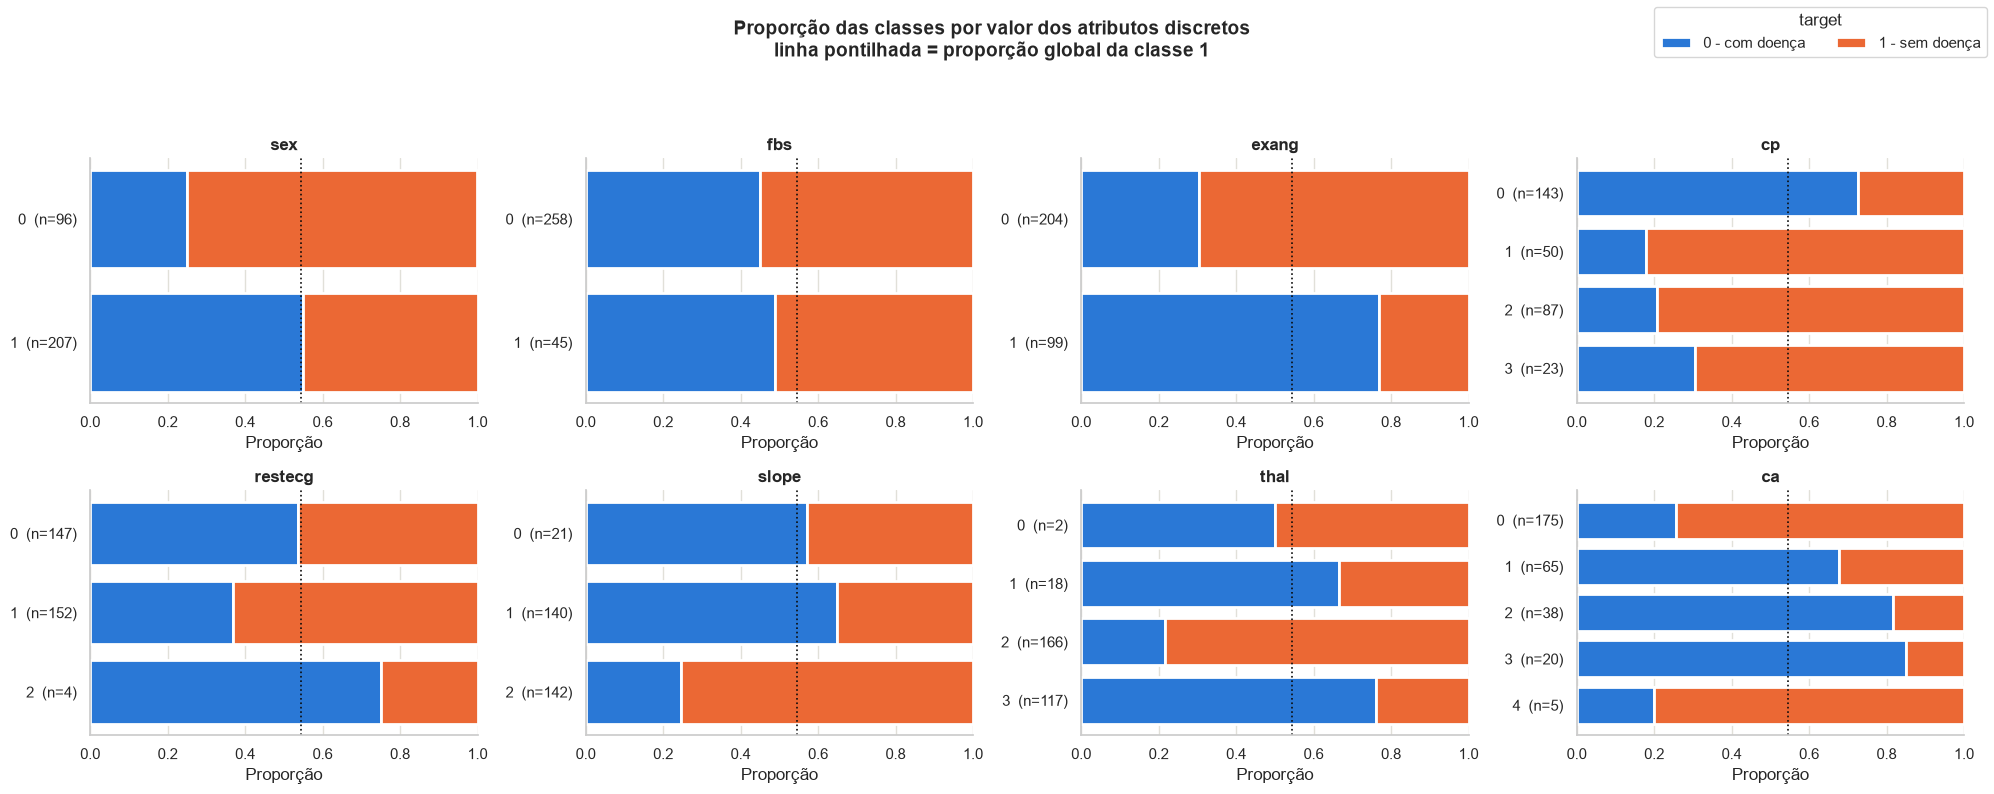

In [13]:
## Barras 100% empilhadas: proporção de cada classe dentro de cada valor do atributo
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, ATR_DISCRETOS):
    tabela = pd.crosstab(df_original[col], df_original[ALVO], normalize="index")
    n = df_original[col].value_counts().sort_index()
    rotulos = [f"{int(v)}  (n={n[v]})" for v in tabela.index]
    esquerda = np.zeros(len(tabela))
    for classe in [0, 1]:
        ax.barh(rotulos, tabela[classe], left=esquerda, color=CORES_CLASSE[classe],
                edgecolor="white", linewidth=2, label=NOMES_CLASSE[classe])
        esquerda += tabela[classe].values
    ax.axvline(df_original[ALVO].mean(), color="#0b0b0b", linestyle=":", linewidth=1.2)
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_title(col)
    ax.set_xlabel("Proporção")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="target", loc="upper right", ncol=2)
fig.suptitle("Proporção das classes por valor dos atributos discretos\n"
             "linha pontilhada = proporção global da classe 1", fontweight="bold", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

Sabendo que a classe target estava com valores trocados (no arquivo "correto", a classe 0 é a dos pacientes **com doença**), fazemos uma análise dos **padrões observados**. Se a interpretação médica deles estiver de acordo com essa troca, saberemos que realizamos a análise correta:
- Pacientes com doença têm, em média, **`thalach` mais baixo**, **`oldpeak` mais alto** e idade um pouco maior. `chol` e `trestbps` diferem pouco entre as classes.
- `cp`, `exang`, `ca`, `thal`, `slope` e `sex` mostram diferenças marcantes de proporção entre seus valores: dor no peito **assintomática** (`cp = 0`), angina induzida por exercício (`exang = 1`), mais vasos afetados (`ca` maior) e defeitos na cintilografia (`thal` = 1 ou 3) concentram os casos de doença. Esses padrões são **coerentes com a literatura clínica**, o que corrobora a leitura do alvo feita na Seção 4.3. Já `fbs` praticamente não altera a proporção das classes.
- A relação de `cp`, `slope` e `thal` com o alvo **não é monotônica** nos códigos (ex.: em `cp`, o código 0 tem perfil oposto aos códigos 1, 2 e 3) - evidência usada na Seção 5.5.
- Há categorias **raras**, como `restecg = 2`, com pouquíssimas instâncias, o que pode acabar gerando uma "sub-representação" do grupo.

## 4.6. Correlação entre atributos

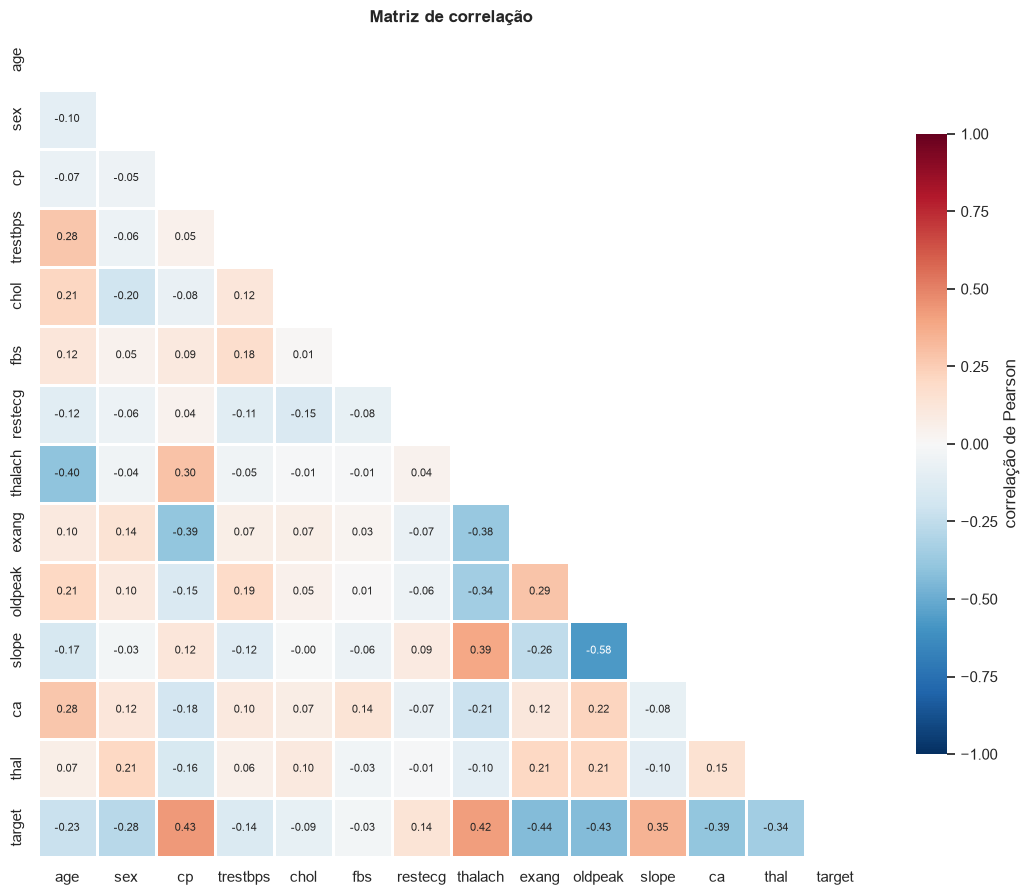

In [14]:
## Matriz de correlação de Pearson (triângulo inferior)
## Obs.: para os atributos nominais o coeficiente é apenas indicativo, pois seus códigos não têm ordem
correlacao = df_original.corr()
mascara = np.triu(np.ones_like(correlacao, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(correlacao, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, linewidths=1, linecolor="white", square=True,
            cbar_kws={"shrink": 0.75, "label": "correlação de Pearson"}, annot_kws={"size": 8}, ax=ax)
ax.grid(False)
ax.set_title("Matriz de correlação")
plt.tight_layout()
plt.show()

Nenhum par de atributos preditivos apresenta correlação muito alta, sob nossa interpretação (o maior valor absoluto fica em torno de 0,6, entre `oldpeak` e `slope`, o que é esperado, já que ambos descrevem o mesmo segmento, ST, no teste de esforço). Assim, **não há redundância forte** que justifique a remoção de atributos. As correlações mais fortes com o alvo envolvem `cp`, `thalach`, `exang`, `oldpeak`, `ca` e `thal`.

## 4.7. Outliers

,limite inferior,limite superior,outliers,%
age,27.25,81.25,0,0.0
trestbps,90.00,170.00,9,3.0
chol,115.75,369.75,5,1.7
thalach,84.75,214.75,1,0.3
oldpeak,-2.40,4.00,5,1.7


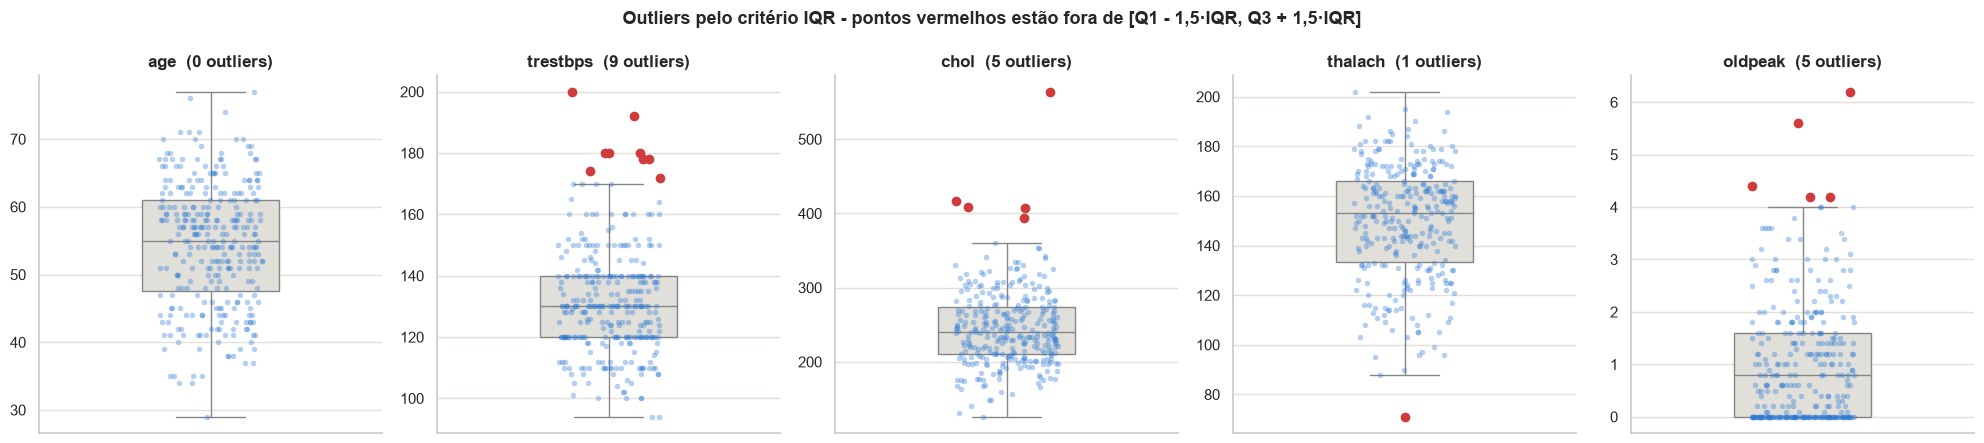

Valores considerados outliers:
  trestbps: [172, 174, 178, 178, 180, 180, 180, 192, 200]
  chol: [394, 407, 409, 417, 564]
  thalach: [71]
  oldpeak: [4.2, 4.2, 4.4, 5.6, 6.2]


In [15]:
def limites_iqr(serie, k=1.5):
    """Limites de Tukey: [Q1 - k*IQR, Q3 + k*IQR]."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

limites = {col: limites_iqr(df_original[col]) for col in ATR_CONTINUOS}
outliers = pd.DataFrame({
    "limite inferior": {c: l[0] for c, l in limites.items()},
    "limite superior": {c: l[1] for c, l in limites.items()},
    "outliers": {c: (~df_original[c].between(*l)).sum() for c, l in limites.items()},
})
outliers["%"] = (100 * outliers["outliers"] / len(df_original)).round(1)
display(outliers.round(2))

fig, axes = plt.subplots(1, 5, figsize=(20, 4.5))
for ax, col in zip(axes, ATR_CONTINUOS):
    inf, sup = limites[col]
    eh_outlier = ~df_original[col].between(inf, sup)
    sns.boxplot(y=df_original[col], ax=ax, color="#e1e0d9", width=0.4, showfliers=False)
    sns.stripplot(y=df_original[col][~eh_outlier], ax=ax, color=COR_PRINCIPAL, alpha=0.35, size=4, jitter=0.15)
    sns.stripplot(y=df_original[col][eh_outlier], ax=ax, color=COR_ALERTA, size=7, jitter=0.15)
    ax.set_title(f"{col}  ({eh_outlier.sum()} outliers)")
    ax.set_ylabel("")
fig.suptitle("Outliers pelo critério IQR - pontos vermelhos estão fora de [Q1 - 1,5·IQR, Q3 + 1,5·IQR]",
             fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

print("Valores considerados outliers:")
for col in ATR_CONTINUOS:
    valores = sorted(df_original[col][~df_original[col].between(*limites[col])].tolist())
    if valores:
        print(f"  {col}: {valores}")

Há *outliers* estatísticos em `trestbps`, `chol`, `thalach` e `oldpeak` (poucos casos, até ~3% por atributo). Todos os valores são, porém, **clinicamente plausíveis** (ex.: pressão de 200 mm Hg ou colesterol de 564 mg/dl ocorrem em pacientes reais e podem ser justamente informativos), e nenhum é erro de registro (Seção 4.3). Por isso, **escolhemos manter essas instâncias**.

## 4.8. Resumo da EDA

O conjunto de dados é pequeno (303 registros, 302 pacientes únicos, 13 atributos), está quase balanceado e não possui valores faltantes explícitos. Os principais problemas encontrados, e que serão tratados na Seção 5, são:

- **uma instância duplicada** (Seção 4.2), artefato da versão do Kaggle;
- **valores ausentes codificados como valores fora do domínio** em `ca` (4) e `thal` (0), confirmados pela comparação com a base original da UCI (Seção 4.3), que também revelou que o **alvo tem o sentido oposto** ao da descrição do Kaggle;
- **atributos categóricos nominais armazenados como inteiros**, com relação não monotônica com o alvo (Seção 4.5);
- **escalas muito diferentes** entre os atributos numéricos (Seção 4.1; detalhada na Seção 5.6).

*Outliers* foram identificados, mas mantidos por serem clinicamente plausíveis (Seção 4.7), e não há redundância forte entre atributos (Seção 4.6).

# 5. Pré-processamento dos dados

Cada decisão abaixo é consequência de uma evidência da EDA. A ordem das etapas foi escolhida para evitar *data leakage*:

1. **Antes da divisão treino/teste** ficam apenas regras **determinísticas**, aplicadas linha a linha, sem aprender nenhuma estatística dos dados: a _recodificação do alvo_ (5.1) e a _remoção da duplicata_ (5.2).
2. **Divisão treino/teste** (5.3).
3. As etapas que **aprendem parâmetros** (imputação, codificação e padronização - 5.4 a 5.6) são reunidas em um `Pipeline` (5.7), que é ajustado **somente com os dados de treino** de cada *fold* da validação cruzada.

## 5.1. Recodificação do atributo-alvo

**Evidenciado pela Seção 4.3,** no arquivo original, `target = 1` corresponde aos pacientes **sem** doença. Portanto, decidimos criar o alvo de modelagem `doenca` = 1 - `target`, de forma que **1 = com doença (tendência a ataque cardíaco)** seja a **classe positiva**. Isso é necessário porque a métrica principal (F1, discutida posteriormente na Seção 6.3) e as métricas de precisão e *recall* são calculadas sobre a classe positiva - sem a recodificação, mediriam a capacidade de detectar pacientes *saudáveis*. É uma troca de rótulos determinística e arbitrária, sem nenhuma informação aprendida, apenas para destacar o objetivo do trabalho (detectar a tendência de ataques cardíacos).

In [16]:
ALVO_MODELO = "doenca"
df = df_original.copy()
df[ALVO_MODELO] = 1 - df[ALVO]                 # 1 = com doença (classe positiva); 0 = sem doença
NOMES_DOENCA = {0: "0 - sem doença", 1: "1 - com doença"}

print(pd.crosstab(df[ALVO], df[ALVO_MODELO], rownames=["target (original)"], colnames=["doenca (modelagem)"]))
df = df.drop(columns=ALVO)

doenca (modelagem)    0    1
target (original)           
0                     0  138
1                   165    0


## 5.2. Remoção da instância duplicada

**Evidenciado pelas Seções 4.2 e 4.3,** as linhas 163 e 164 são idênticas e correspondem ao **mesmo** paciente da base original (um artefato/falha da versão do Kaggle). Portanto, decidimos **manter apenas uma** cópia. A remoção é feita **antes** da divisão: se as duas cópias ficassem uma no treino e outra no teste (ou em *folds* diferentes), o modelo seria avaliado em um exemplo já visto, inflando o desempenho.

In [17]:
n_antes = len(df)
df = df.drop_duplicates(keep="first").reset_index(drop=True)
print(f"Instâncias: {n_antes} → {len(df)} (removida(s) {n_antes - len(df)} duplicata(s))")
print("Distribuição do alvo de modelagem:", df[ALVO_MODELO].value_counts().sort_index().rename(index=NOMES_DOENCA).to_dict())

Instâncias: 303 → 302 (removida(s) 1 duplicata(s))
Distribuição do alvo de modelagem: {'0 - sem doença': 164, '1 - com doença': 138}


## 5.3. Divisão dos dados em treino e teste

Reservamos **20% dos dados para teste**, com **estratificação pelo alvo** (preserva a proporção das classes) e semente fixa. O conjunto de teste simula dados nunca vistos e **não é usado no T1**: fica reservado para a avaliação final no T2. O *spot-checking* (Seção 7) usa apenas o conjunto de treino.

In [18]:
X = df.drop(columns=ALVO_MODELO)
y = df[ALVO_MODELO]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("Tamanho treino:", X_train.shape)
print("Tamanho teste: ", X_test.shape)
print(pd.DataFrame({"treino": y_train.value_counts(normalize=True), "teste": y_test.value_counts(normalize=True)})
      .rename(index=NOMES_DOENCA).round(3))

Tamanho treino: (241, 13)
Tamanho teste:  (61, 13)
                treino  teste
doenca                       
0 - sem doença   0.544  0.541
1 - com doença   0.456  0.459


## 5.4. Valores ausentes: marcação e imputação pela mediana

**Evidenciado pela Seção 4.3,** `ca = 4` e `thal = 0` não são categorias reais, mas a marcação dos valores ausentes (`?`) da base original. Mantidos como estão, os modelos interpretariam esses códigos como informação (ex.: "4 vasos afetados"). São apenas 6 valores ausentes (4 em `ca` e 2 em `thal`, cerca de 2% das instâncias), e nenhuma instância tem mais de um atributo ausente.

Portanto, decidimos realizar:
1. A **Marcação**, ou seja, converter esses códigos em `NaN`/"ausente". É uma regra fixa por linha (não aprende nada dos dados), aplicada igualmente a treino e teste.
2. E, posteriormente, a **Imputação pela Mediana** (`SimpleImputer(strategy="median")`), preservando todas as instâncias de uma base que já é pequena. A mediana é robusta a valores extremos e, por ser **calculada apenas nos dados de treino** (dentro do `Pipeline`, em cada *fold*), não usa informação do conjunto de validação ou de teste.

Destacamos que `thal` é um atributo nominal, para o qual a medida conceitualmente adequada seria a moda. Nestes dados, porém, a mediana e a moda coincidem (código 2 = normal; em `ca`, ambas valem 0), de modo que o valor imputado é o mesmo.

In [19]:
## 1) Marcação: códigos fora do domínio passam a ser valores faltantes explícitos (regra determinística)
def marcar_ausentes(dados):
    dados = dados.copy()
    for col in ["ca", "thal"]:
        dados[col] = dados[col].where(dados[col].isin(DOMINIO_ESPERADO[col]))
    return dados

X_train, X_test = marcar_ausentes(X_train), marcar_ausentes(X_test)

## 2) Onde estão os valores ausentes e quais valores serão imputados (calculados SOMENTE no treino)
faltantes = pd.DataFrame({"treino": X_train.isnull().sum(), "teste": X_test.isnull().sum()})
faltantes = faltantes[faltantes.sum(axis=1) > 0]
faltantes["mediana no treino"] = [X_train[c].median() for c in faltantes.index]
faltantes["moda no treino"] = [X_train[c].mode()[0] for c in faltantes.index]
display(faltantes)

,treino,teste,mediana no treino,moda no treino
ca,1,3,0.0,0.0
thal,1,1,2.0,2.0


## 5.5. Codificação dos atributos categóricos

Observamos que a **transformação de categórico em numérico não é necessária** - todos os atributos já estão armazenados como números (Seção 4.1).

Já a **codificação *one-hot* dos atributos nominais é necessária**. **Evidenciado pelas Seções 4.1 e 4.5,** `cp`, `restecg`, `slope` e `thal` são categorias armazenadas como inteiros, e a relação de seus códigos com o alvo **não é monotônica** (ex.: em `cp`, o código 0 tem perfil oposto aos códigos 1, 2 e 3). Mantidos como inteiros, algoritmos baseados em distância (KNN), lineares (Regressão Logística) e redes neurais assumiriam uma ordem e distâncias inexistentes entre as categorias. **Decidimos**, portanto, **aplicar `OneHotEncoder` aos 4 atributos nominais** (13 → 22 colunas). Usamos `handle_unknown="ignore"` porque há categorias raras (ex.: `restecg = 2`) que podem não aparecer em algum *fold* de treino. Os atributos binários já estão em 0/1 e `ca` é uma contagem ordenada, portanto permanecem como estão. Árvores e *ensembles* de árvores não são prejudicados pela codificação.

## 5.6. Normalização dos atributos numéricos

Como consequência das escalas dos atributos numéricos serem muito heterogêneas (tabela e gráficos abaixo, calculados no treino), percebemos a **necessidade da normalização**: `chol` tem amplitude dezenas de vezes maior que a de `oldpeak`, por exemplo. Em KNN (distância), especialmente, os atributos de maior amplitude dominariam o aprendizado de forma arbitrária; árvores e *ensembles* de árvores, contudo, não são afetados. Assim, decidimos **padronizar** (*z-score*, `StandardScaler`) os **atributos numéricos** e `ca`. O *scaler* é ajustado **somente no treino** e apenas *aplicado* aos demais dados.

,mínimo,máximo,amplitude,desvio padrão
chol,126.0,564.0,438.0,53.44
thalach,88.0,202.0,114.0,21.97
trestbps,94.0,200.0,106.0,17.59
age,29.0,77.0,48.0,9.01
oldpeak,0.0,6.2,6.2,1.17


A maior amplitude (chol) é 71x a menor (oldpeak).


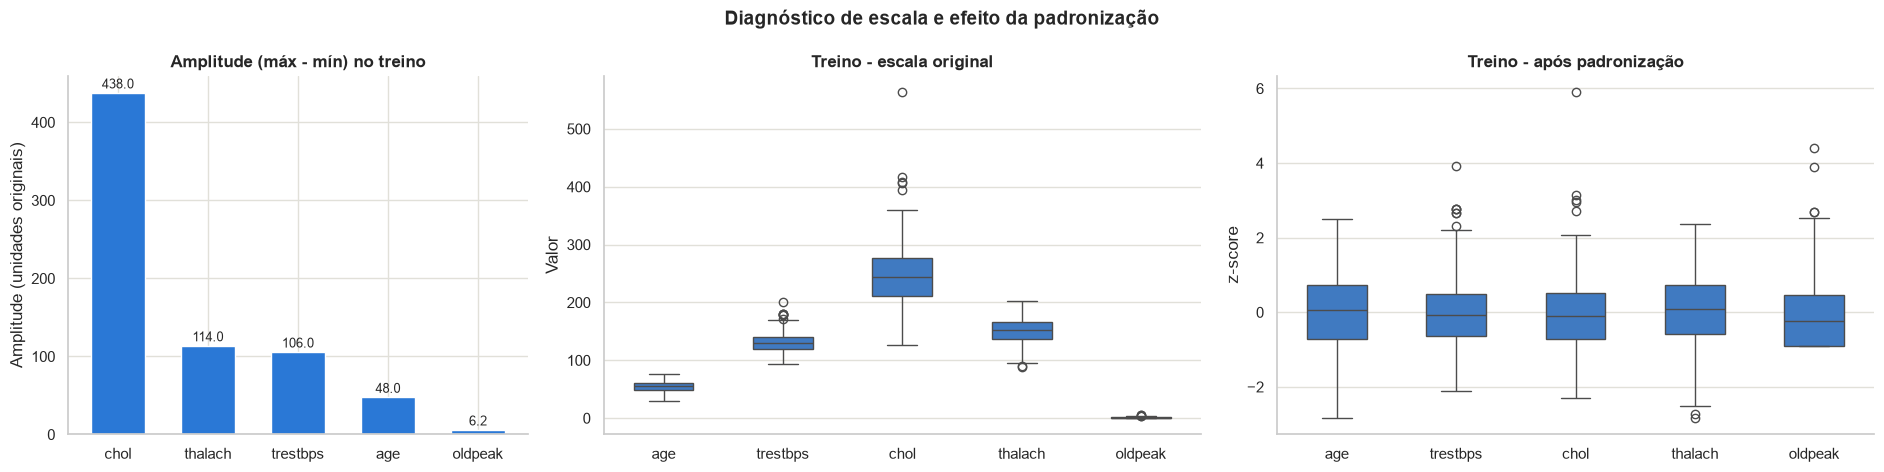

          média treino  média teste  desvio treino  desvio teste
age                0.0       -0.056            1.0         1.023
trestbps           0.0        0.097            1.0         0.991
chol              -0.0       -0.221            1.0         0.811
thalach            0.0       -0.080            1.0         1.195
oldpeak           -0.0       -0.076            1.0         0.978


In [20]:
## Amplitude e desvio padrão de cada atributo numérico (treino)
escala = pd.DataFrame({
    "mínimo": X_train[ATR_CONTINUOS].min(),
    "máximo": X_train[ATR_CONTINUOS].max(),
    "amplitude": X_train[ATR_CONTINUOS].max() - X_train[ATR_CONTINUOS].min(),
    "desvio padrão": X_train[ATR_CONTINUOS].std(),
}).sort_values("amplitude", ascending=False)
display(escala.round(2))
razao_amplitude = escala["amplitude"].max() / escala["amplitude"].min()
print(f"A maior amplitude ({escala.index[0]}) é {razao_amplitude:.0f}x a menor ({escala.index[-1]}).")

## Padronização AJUSTADA NO TREINO e aplicada ao treino e ao teste
scaler = StandardScaler().fit(X_train[ATR_CONTINUOS])
X_train_pad = pd.DataFrame(scaler.transform(X_train[ATR_CONTINUOS]), columns=ATR_CONTINUOS)
X_test_pad = pd.DataFrame(scaler.transform(X_test[ATR_CONTINUOS]), columns=ATR_CONTINUOS)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), gridspec_kw={"width_ratios": [1, 1.3, 1.3]})
escala["amplitude"].plot.bar(ax=axes[0], color=COR_PRINCIPAL, rot=0, width=0.6)
rotular_barras(axes[0], fmt="{:.1f}")
axes[0].set_title("Amplitude (máx - mín) no treino")
axes[0].set_ylabel("Amplitude (unidades originais)")
sns.boxplot(data=X_train[ATR_CONTINUOS], ax=axes[1], color=COR_PRINCIPAL, width=0.5)
axes[1].set_title("Treino - escala original")
axes[1].set_ylabel("Valor")
sns.boxplot(data=X_train_pad, ax=axes[2], color=COR_PRINCIPAL, width=0.5)
axes[2].set_title("Treino - após padronização")
axes[2].set_ylabel("z-score")
fig.suptitle("Diagnóstico de escala e efeito da padronização", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## No treino, média 0 e desvio 1 por construção; no teste, apenas próximos disso (parâmetros vêm do treino)
print(pd.DataFrame({"média treino": X_train_pad.mean(), "média teste": X_test_pad.mean(),
                    "desvio treino": X_train_pad.std(ddof=0), "desvio teste": X_test_pad.std(ddof=0)}).round(3))

## 5.7. *Pipeline* de pré-processamento

As etapas que aprendem parâmetros (5.4 a 5.6) são reunidas em um `ColumnTransformer`. Na Seção 7, ele é combinado com cada classificador em um `Pipeline`, de forma que, em cada *fold* da validação cruzada, a mediana, as categorias do *one-hot* e os parâmetros da padronização sejam **reaprendidos apenas com os dados de treino daquele *fold***.

In [21]:
ATR_PADRONIZADOS = ATR_CONTINUOS + ATR_ORDINAIS

preprocessador = ColumnTransformer([
    ("numericos", Pipeline([("imputacao", SimpleImputer(strategy="median")),
                            ("padronizacao", StandardScaler())]), ATR_PADRONIZADOS),
    ("binarios", "passthrough", ATR_BINARIOS),
    ("nominais", Pipeline([("imputacao", SimpleImputer(strategy="median")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), ATR_NOMINAIS),
])

## Conferência (apenas ilustrativa): ajuste no treino e dimensão resultante
X_train_prep = pd.DataFrame(preprocessador.fit_transform(X_train), columns=preprocessador.get_feature_names_out())
print(f"Atributos: {X_train.shape[1]} originais → {X_train_prep.shape[1]} após o pré-processamento")
print(f"Valores faltantes após a imputação: {X_train_prep.isnull().sum().sum()}")
X_train_prep.head()

Atributos: 13 originais → 22 após o pré-processamento
Valores faltantes após a imputação: 0


,numericos__age,numericos__trestbps,numericos__chol,numericos__thalach,numericos__oldpeak,numericos__ca,binarios__sex,binarios__fbs,binarios__exang,nominais__cp_0.0,...,nominais__cp_3.0,nominais__restecg_0.0,nominais__restecg_1.0,nominais__restecg_2.0,nominais__slope_0.0,nominais__slope_1.0,nominais__slope_2.0,nominais__thal_1.0,nominais__thal_2.0,nominais__thal_3.0
0,-0.058164,-0.413493,0.321129,-1.866471,0.978431,0.437949,1.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,0.053086,-0.071634,0.246118,0.231440,-0.911420,-0.696951,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
2,-0.058164,0.042319,0.733686,0.413867,-0.911420,0.437949,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3,-0.058164,-1.325116,1.127491,0.277047,-0.911420,-0.696951,1.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,1.276841,1.637659,-0.053923,-1.364797,-0.911420,2.707749,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


# 6. Definição da abordagem, dos algoritmos e da estratégia de avaliação

## 6.1. Abordagem

O problema é de **classificação binária**: o atributo-alvo indica se o paciente **possui ou não** doença cardíaca (tendência a ataque cardíaco), isto é, assume apenas duas categorias, sem significado numérico contínuo.

## 6.2. Algoritmos

Foram selecionados 6 algoritmos com **vieses indutivos diversificados** (quanto à representação da hipótese, à estratégia de aprendizado e ao tipo de modelagem), usando **valores padrão** de hiperparâmetros (sem otimização, conforme o escopo do T1) e semente fixa nos algoritmos com componente aleatório. São eles:

| Algoritmo | Representação / estratégia | Modelagem | Configuração |
|---|---|---|---|
| KNN | Baseado em instâncias (distância) | Não linear, não paramétrico, preguiçoso | padrão (`n_neighbors=5`) |
| Árvore de Decisão | Simbólico (regras em árvore) | Não linear, não paramétrico | padrão (sem poda) |
| Regressão Logística | Linear, probabilístico (otimização da verossimilhança) | Linear, paramétrico | padrão |
| Rede Neural (MLP) | Conexionista (otimização por gradiente) | Não linear, paramétrico | padrão, exceto `max_iter=1000` |
| Random Forest | *Ensemble* de árvores por *bagging* | Não linear | padrão (100 árvores) |
| Gradient Boosting | *Ensemble* de árvores por *boosting* | Não linear | padrão (100 estimadores) |

A única variação em relação aos valores padrão de hiperparâmetros é `max_iter=1000` na Rede Neural: com o padrão (200 iterações), o otimizador poderia parar antes de convergir em uma base pequena, o que compararia um modelo "incompleto", então decidimos aumentá-lo para garantir. Esse ajuste não "otimiza" o modelo, apenas garante que o treinamento termine.

In [22]:
MODELOS = {
    "KNN": KNeighborsClassifier(),
    "Árvore de Decisão": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Regressão Logística": LogisticRegression(),
    "Rede Neural (MLP)": MLPClassifier(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
for nome, modelo in MODELOS.items():
    print(f"{nome:20s} {modelo}")

KNN                  KNeighborsClassifier()
Árvore de Decisão    DecisionTreeClassifier(random_state=42)
Regressão Logística  LogisticRegression()
Rede Neural (MLP)    MLPClassifier(max_iter=1000, random_state=42)
Random Forest        RandomForestClassifier(random_state=42)
Gradient Boosting    GradientBoostingClassifier(random_state=42)


## 6.3. Métricas de desempenho

Escolhemos como **métrica principal o F1-score da classe positiva (1 = com doença).** O F1 é a média harmônica entre **precisão** (dos pacientes apontados como doentes, quantos realmente são) e ***recall*** (dos pacientes doentes, quantos o modelo encontra). Em um problema médico, os dois tipos de erro têm custos diferentes: deixar de identificar um paciente doente (falso negativo) é grave, mas um modelo que classifica todos como doentes também não é útil. O F1 só é alto quando ambos são bons.

Como as classes estão quase balanceadas (Seção 4.4), a acurácia **não é enganosa** neste problema e tende a ordenar os modelos de forma parecida, porém, por ela tratar os dois tipos de erro como equivalentes e não informar sobre a classe de interesse, usamos ela apenas como métrica **complementar**.

Com isso, temos como **métricas avaliadas:** F1 (principal), acurácia, precisão, *recall* e ROC-AUC (capacidade de ordenar pacientes por risco, independentemente do limiar de decisão). Em cada avaliação também registramos a matriz de confusão (VP, FP, FN, VN).

In [23]:
METRICAS = ["F1", "Acurácia", "Precisão", "Recall", "ROC-AUC"]
METRICA_PRINCIPAL = "F1"
CONFUSAO = ["VN", "FP", "FN", "VP"]


def metricas_e_confusao(estimador, X_aval, y_aval):
    """Calcula todas as métricas e a matriz de confusão em um fold de validação (classe positiva = 1)."""
    y_pred = estimador.predict(X_aval)
    y_prob = estimador.predict_proba(X_aval)[:, 1]
    vn, fp, fn, vp = confusion_matrix(y_aval, y_pred, labels=[0, 1]).ravel()
    return {"F1": f1_score(y_aval, y_pred), "Acurácia": accuracy_score(y_aval, y_pred),
            "Precisão": precision_score(y_aval, y_pred, zero_division=0), "Recall": recall_score(y_aval, y_pred),
            "ROC-AUC": roc_auc_score(y_aval, y_prob), "VN": vn, "FP": fp, "FN": fn, "VP": vp}

## 6.4. Estratégia de validação

**Evidenciada pelas Seções 4.1 e 5.3,** a base é pequena - 302 instâncias, 241 no treino. Com um único *holdout*, a estimativa de desempenho dependeria muito de quais pacientes caíssem em cada lado da divisão (alta variância). Consequentemente, optamos pela **validação cruzada estratificada repetida** (`RepeatedStratifiedKFold`) sobre o conjunto de treino, com **5 *folds* × 10 repetições = 50 avaliações por algoritmo**:

- **Estratificada**, para manter a proporção das classes em cada *fold*;
- **5 *folds***, para que cada *fold* de validação tenha ~48 instâncias (estimativas de F1 menos ruidosas do que com 10 *folds* de ~24);
- **10 repetições** com embaralhamentos diferentes, para obter a distribuição do desempenho (média, desvio padrão e *boxplots*);
- **Mesmas divisões para todos os algoritmos** (semente fixa no `RepeatedStratifiedKFold`), garantindo uma comparação justa.

Como o *nested CV* serve para separar a **otimização de hiperparâmetros** (laço interno) da **estimativa de desempenho** (laço externo), mantivemos nossa escolha do Cross-Validation comum, justamente pois no *spot-checking* os algoritmos usam hiperparâmetros padrão, e, portanto, não há laço interno a executar - o *nested CV* se reduziria a um CV comum. Pretendemos usá-lo no T2, quando houver otimização.

In [24]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
print(f"Total de avaliações por algoritmo: {cv.get_n_splits()}")

Total de avaliações por algoritmo: 50


# 7. *Spot-checking* de algoritmos

Cada algoritmo é combinado com o pré-processamento (Seção 5.7) em um `Pipeline` e avaliado com a mesma validação cruzada (Seção 6.4). Em cada uma das 50 avaliações, o `Pipeline` inteiro (imputação, *one-hot*, padronização e classificador) é ajustado apenas nos 4 *folds* de treino e avaliado no *fold* restante.

Para cada algoritmo são apresentados:
- **estatísticas de cada métrica** nas 50 avaliações (média, desvio padrão, mínimo e máximo);
- a **distribuição do F1** nas 50 avaliações;
- a **matriz de confusão média por repetição** - como cada repetição percorre todo o treino uma vez, ela mostra, em média, quantos dos 241 pacientes de treino caem em cada célula.

In [25]:
resultados = {}


def avaliar_modelo(nome):
    """Executa a validação cruzada de um algoritmo e apresenta suas estatísticas."""
    pipeline = Pipeline([("preprocessamento", preprocessador), ("classificador", MODELOS[nome])])
    avaliacao = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=metricas_e_confusao, n_jobs=-1)
    res = pd.DataFrame({m: avaliacao[f"test_{m}"] for m in METRICAS + CONFUSAO})
    resultados[nome] = res

    ## Estatísticas das métricas nas 50 avaliações
    estatisticas = res[METRICAS].agg(["mean", "std", "min", "max"]).T
    estatisticas.columns = ["média", "desvio padrão", "mínimo", "máximo"]
    display(estatisticas.round(3))

    ## Distribuição do F1 e matriz de confusão média por repetição
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
    sns.histplot(res["F1"], bins=np.arange(0.55, 1.0001, 0.025), ax=axes[0], color=COR_PRINCIPAL, edgecolor="white")
    axes[0].axvline(res["F1"].mean(), color="#0b0b0b", linestyle="--", linewidth=1.5,
                    label=f"média = {res['F1'].mean():.3f}")
    axes[0].set_xlim(0.55, 1.0)
    axes[0].set_title("F1 nas 50 avaliações")
    axes[0].set_xlabel("F1-score")
    axes[0].set_ylabel("Nº de avaliações")
    axes[0].legend(fontsize=9)

    matriz_media = res[CONFUSAO].sum().to_numpy().reshape(2, 2) / cv.n_repeats
    ConfusionMatrixDisplay(matriz_media, display_labels=["sem doença", "com doença"]).plot(
        ax=axes[1], cmap="Blues", values_format=".1f", colorbar=False)
    axes[1].grid(False)
    axes[1].set_title("Matriz de confusão média por repetição")
    axes[1].set_xlabel("Classe prevista")
    axes[1].set_ylabel("Classe real")
    fig.suptitle(nome, fontweight="bold", fontsize=14)
    plt.tight_layout()
    plt.show()

## 7.1. KNN (*k-Nearest Neighbors*)

Classifica um paciente pela **votação das classes dos *k* vizinhos mais próximos** (aqui, *k* = 5, distância euclidiana) no espaço de atributos. Não constrói um modelo explícito: apenas armazena o treino (aprendizado *preguiçoso*). É não paramétrico e muito sensível à escala dos atributos e à dimensionalidade.

,média,desvio padrão,mínimo,máximo
F1,0.818,0.055,0.667,0.933
Acurácia,0.837,0.046,0.729,0.938
Precisão,0.833,0.061,0.714,1.000
Recall,0.808,0.076,0.545,0.955
ROC-AUC,0.872,0.051,0.742,0.959


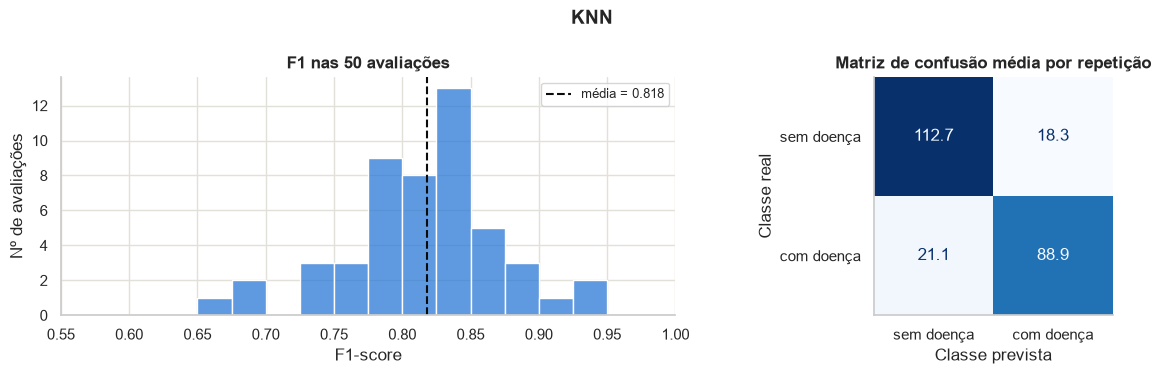

In [26]:
avaliar_modelo("KNN")

## 7.2. Árvore de Decisão

Particiona o espaço de atributos de forma recursiva, escolhendo em cada nó o teste que mais aumenta a pureza das classes (índice de Gini). Gera regras interpretáveis e não é afetada pela escala. Sem poda, cresce até separar o treino, o que tende a causar **alta variância** (sobreajuste).

,média,desvio padrão,mínimo,máximo
F1,0.729,0.056,0.600,0.857
Acurácia,0.749,0.053,0.583,0.875
Precisão,0.725,0.068,0.536,0.900
Recall,0.740,0.082,0.591,0.909
ROC-AUC,0.749,0.053,0.591,0.871


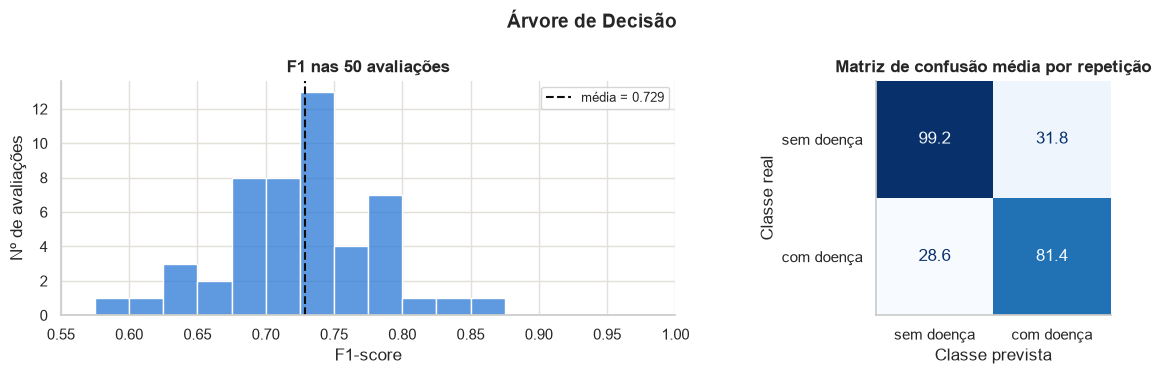

In [27]:
avaliar_modelo("Árvore de Decisão")

## 7.3. Regressão Logística

Modelo **linear** que estima a probabilidade da classe positiva aplicando a função logística a uma combinação linear dos atributos. Os pesos são obtidos por máxima verossimilhança, com regularização L2. A fronteira de decisão é linear e os coeficientes são interpretáveis.

,média,desvio padrão,mínimo,máximo
F1,0.826,0.059,0.647,0.933
Acurácia,0.848,0.048,0.750,0.938
Precisão,0.864,0.068,0.708,1.000
Recall,0.798,0.090,0.500,0.955
ROC-AUC,0.909,0.042,0.811,0.969


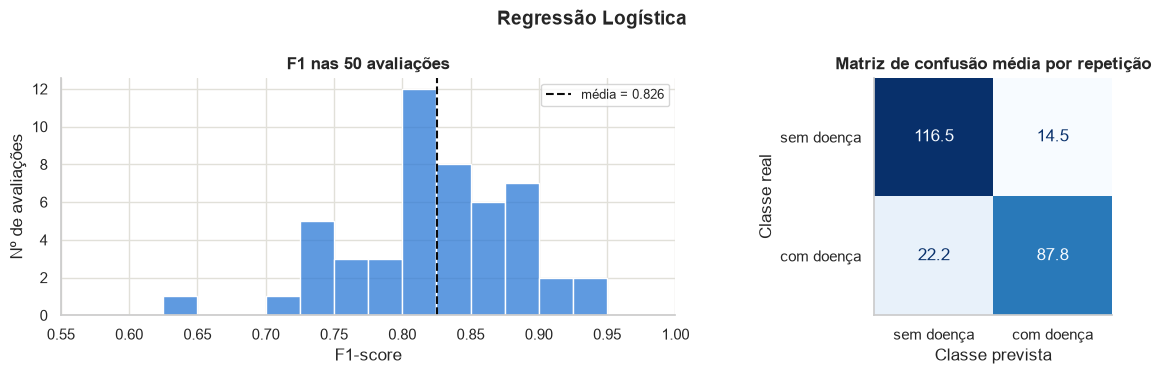

In [28]:
avaliar_modelo("Regressão Logística")

## 7.4. Rede Neural (MLP)

*Perceptron* multicamadas: neurônios organizados em camadas (aqui, uma camada oculta com 100 neurônios e ativação ReLU), com pesos ajustados por retropropagação do gradiente (otimizador Adam). Pode representar fronteiras não lineares complexas, mas exige mais dados e é sensível à escala.

,média,desvio padrão,mínimo,máximo
F1,0.773,0.062,0.622,0.878
Acurácia,0.797,0.057,0.646,0.896
Precisão,0.801,0.092,0.609,1.000
Recall,0.756,0.085,0.500,0.909
ROC-AUC,0.867,0.053,0.755,0.956


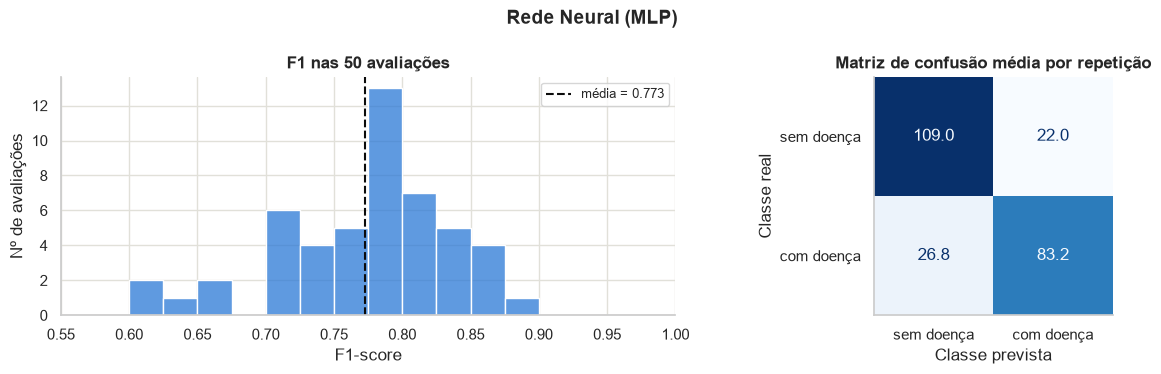

In [29]:
avaliar_modelo("Rede Neural (MLP)")

## 7.5. Random Forest

*Ensemble* de 100 árvores de decisão, cada uma treinada em uma amostra *bootstrap* do treino e considerando um subconjunto aleatório de atributos em cada divisão. A predição é a votação das árvores, o que **reduz a variância** de uma árvore isolada (*bagging*).

,média,desvio padrão,mínimo,máximo
F1,0.809,0.053,0.667,0.913
Acurácia,0.829,0.047,0.688,0.917
Precisão,0.830,0.074,0.652,1.000
Recall,0.796,0.079,0.591,0.955
ROC-AUC,0.904,0.040,0.800,0.970


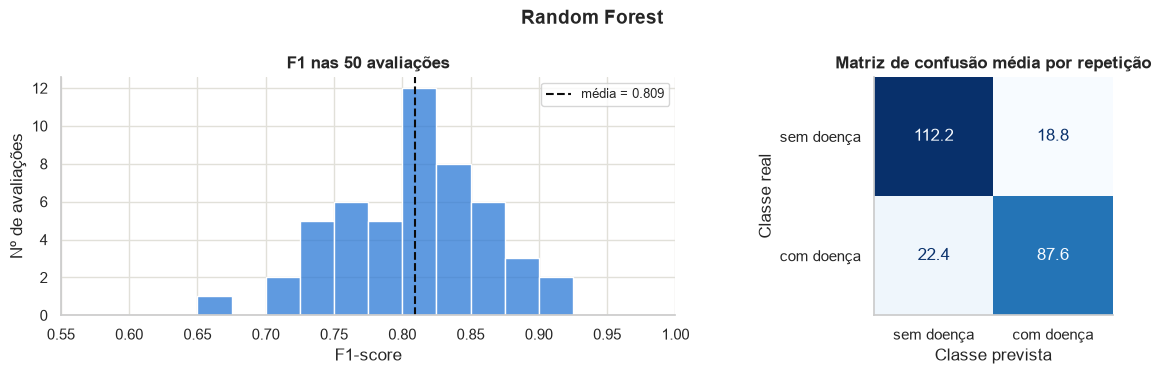

In [30]:
avaliar_modelo("Random Forest")

## 7.6. Gradient Boosting

*Ensemble* em que 100 árvores rasas (profundidade 3) são adicionadas **sequencialmente**, cada uma ajustada para corrigir os erros (o gradiente da função de perda) do conjunto anterior, com taxa de aprendizado 0,1. Reduz principalmente o **viés**.

,média,desvio padrão,mínimo,máximo
F1,0.781,0.053,0.634,0.889
Acurácia,0.800,0.047,0.688,0.896
Precisão,0.786,0.062,0.654,0.900
Recall,0.782,0.082,0.591,0.955
ROC-AUC,0.878,0.045,0.767,0.965


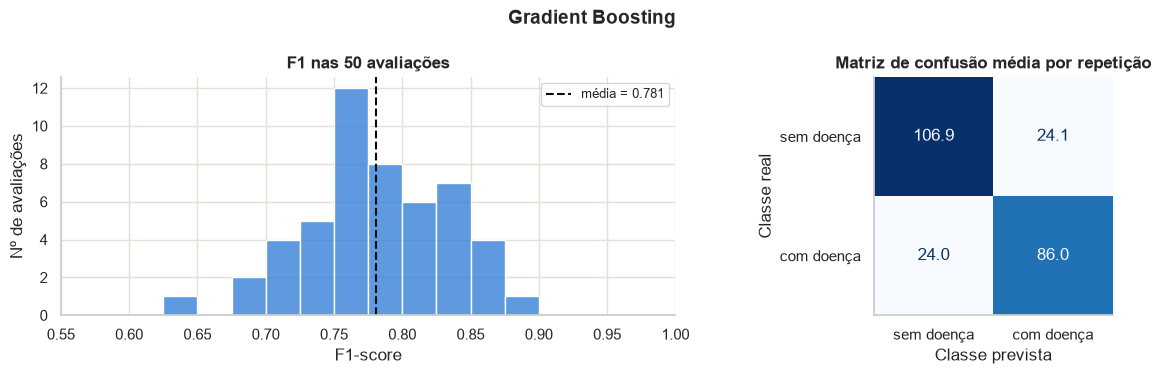

In [31]:
avaliar_modelo("Gradient Boosting")

# 8. Sumarização dos resultados

## 8.1. Tabela comparativa

Média ± desvio padrão de cada métrica nas 50 avaliações, com os algoritmos ordenados pela métrica principal (F1).

In [32]:
## Formato longo: uma linha por (algoritmo, avaliação), útil para tabelas e gráficos
resultados_longos = pd.concat(resultados, names=["Algoritmo", "avaliacao"]).reset_index()

media = resultados_longos.groupby("Algoritmo")[METRICAS].mean()
desvio = resultados_longos.groupby("Algoritmo")[METRICAS].std()
ordem = media[METRICA_PRINCIPAL].sort_values(ascending=False).index

tabela_resultados = (media.map("{:.3f}".format) + " ± " + desvio.map("{:.3f}".format)).loc[ordem]
tabela_resultados.insert(0, "Posição (F1)", range(1, len(ordem) + 1))
display(tabela_resultados)

,Posição (F1),F1,Acurácia,Precisão,Recall,ROC-AUC
Algoritmo,,,,,,
Regressão Logística,1,0.826 ± 0.059,0.848 ± 0.048,0.864 ± 0.068,0.798 ± 0.090,0.909 ± 0.042
KNN,2,0.818 ± 0.055,0.837 ± 0.046,0.833 ± 0.061,0.808 ± 0.076,0.872 ± 0.051
Random Forest,3,0.809 ± 0.053,0.829 ± 0.047,0.830 ± 0.074,0.796 ± 0.079,0.904 ± 0.040
Gradient Boosting,4,0.781 ± 0.053,0.800 ± 0.047,0.786 ± 0.062,0.782 ± 0.082,0.878 ± 0.045
Rede Neural (MLP),5,0.773 ± 0.062,0.797 ± 0.057,0.801 ± 0.092,0.756 ± 0.085,0.867 ± 0.053
Árvore de Decisão,6,0.729 ± 0.056,0.749 ± 0.053,0.725 ± 0.068,0.740 ± 0.082,0.749 ± 0.053


## 8.2. Gráficos comparativos

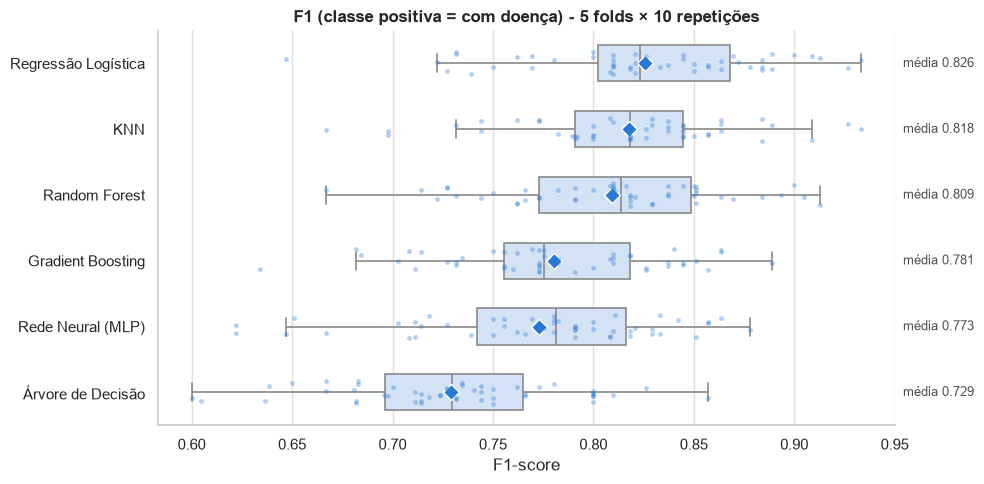

In [33]:
## Distribuição do F1 nas 50 avaliações de cada algoritmo (losango = média)
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=resultados_longos, y="Algoritmo", x=METRICA_PRINCIPAL, order=ordem, ax=ax,
            color="#cde2fb", width=0.55, showfliers=False, linewidth=1.2,
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": COR_PRINCIPAL,
                                       "markeredgecolor": "white", "markersize": 8})
sns.stripplot(data=resultados_longos, y="Algoritmo", x=METRICA_PRINCIPAL, order=ordem, ax=ax,
              color=COR_PRINCIPAL, alpha=0.35, size=3.5, jitter=0.18)
for i, nome in enumerate(ordem):
    ax.annotate(f"média {media.loc[nome, METRICA_PRINCIPAL]:.3f}", (1.0, i), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#52514e",
                xycoords=("axes fraction", "data"))
ax.set_title("F1 (classe positiva = com doença) - 5 folds × 10 repetições")
ax.set_xlabel("F1-score")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

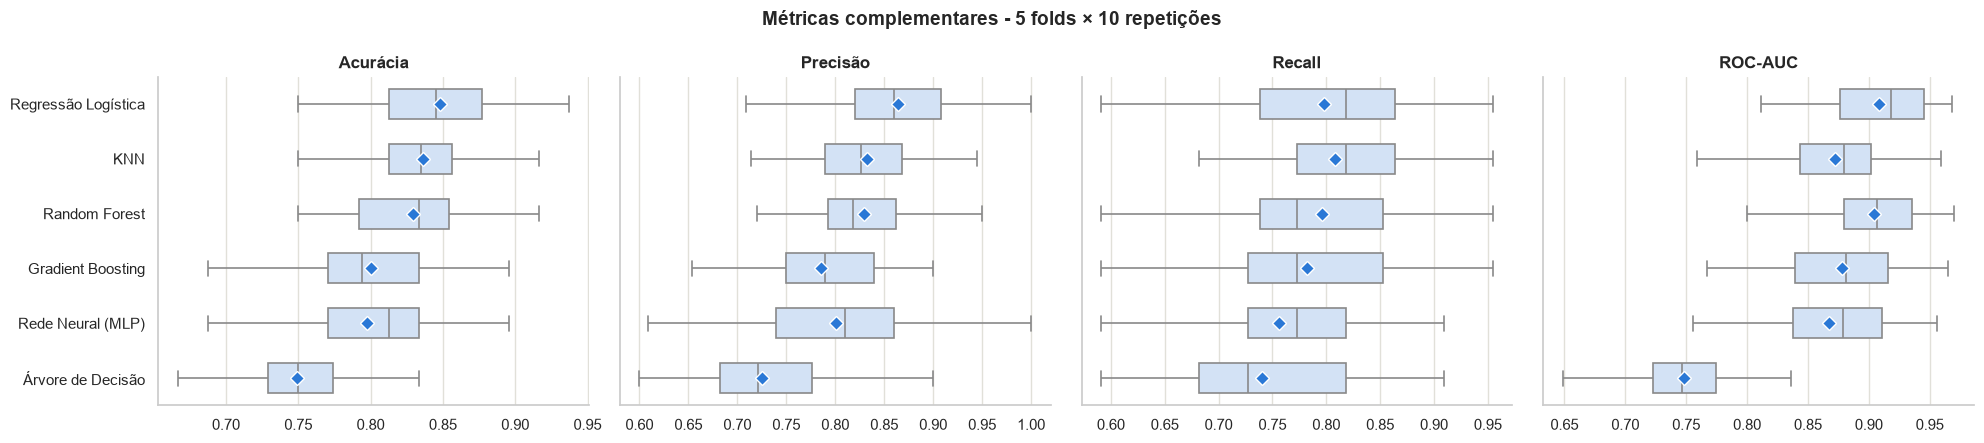

In [34]:
## Métricas complementares (mesma ordem de algoritmos)
complementares = [m for m in METRICAS if m != METRICA_PRINCIPAL]
fig, axes = plt.subplots(1, len(complementares), figsize=(20, 4.5), sharey=True)
for ax, metrica in zip(axes, complementares):
    sns.boxplot(data=resultados_longos, y="Algoritmo", x=metrica, order=ordem, ax=ax,
                color="#cde2fb", width=0.55, showfliers=False, linewidth=1.2,
                showmeans=True, meanprops={"marker": "D", "markerfacecolor": COR_PRINCIPAL,
                                           "markeredgecolor": "white", "markersize": 7})
    ax.set_title(metrica)
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Métricas complementares - 5 folds × 10 repetições", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

## 8.3. Ranking pela métrica principal

Ordenação dos algoritmos pelo F1 médio. A coluna "diferença para o 1º" permite comparar as diferenças entre algoritmos com a variabilidade das estimativas (desvio padrão).

In [35]:
ranking = pd.DataFrame({
    "F1 médio": media[METRICA_PRINCIPAL],
    "desvio padrão": desvio[METRICA_PRINCIPAL],
}).loc[ordem]
ranking["diferença para o 1º"] = ranking["F1 médio"].iloc[0] - ranking["F1 médio"]
ranking.insert(0, "Posição", range(1, len(ranking) + 1))
display(ranking.round(3))
print(f"Melhor algoritmo pelo F1 médio: {ordem[0]}")

,Posição,F1 médio,desvio padrão,diferença para o 1º
Algoritmo,,,,
Regressão Logística,1,0.826,0.059,0.000
KNN,2,0.818,0.055,0.008
Random Forest,3,0.809,0.053,0.016
Gradient Boosting,4,0.781,0.053,0.045
Rede Neural (MLP),5,0.773,0.062,0.053
Árvore de Decisão,6,0.729,0.056,0.097


Melhor algoritmo pelo F1 médio: Regressão Logística


# 9. Conclusão: seleção dos modelos para o T2

**Modelos selecionados pelo grupo para o T2:** **Regressão Logística**, **KNN** e **Random Forest** - os três maiores F1 médios no *spot-checking*.

### Dados de suporte

,Posição (F1),F1,Recall,Precisão,ROC-AUC,Diferença de F1 para o 1º,Selecionado
Algoritmo,,,,,,,
Regressão Logística,1,0.826 ± 0.059,0.798,0.864,0.909,0.000,sim
KNN,2,0.818 ± 0.055,0.808,0.833,0.872,0.008,sim
Random Forest,3,0.809 ± 0.053,0.796,0.830,0.904,0.016,sim
Gradient Boosting,4,0.781 ± 0.053,0.782,0.786,0.878,0.045,não
Rede Neural (MLP),5,0.773 ± 0.062,0.756,0.801,0.867,0.053,não
Árvore de Decisão,6,0.729 ± 0.056,0.740,0.725,0.749,0.097,não


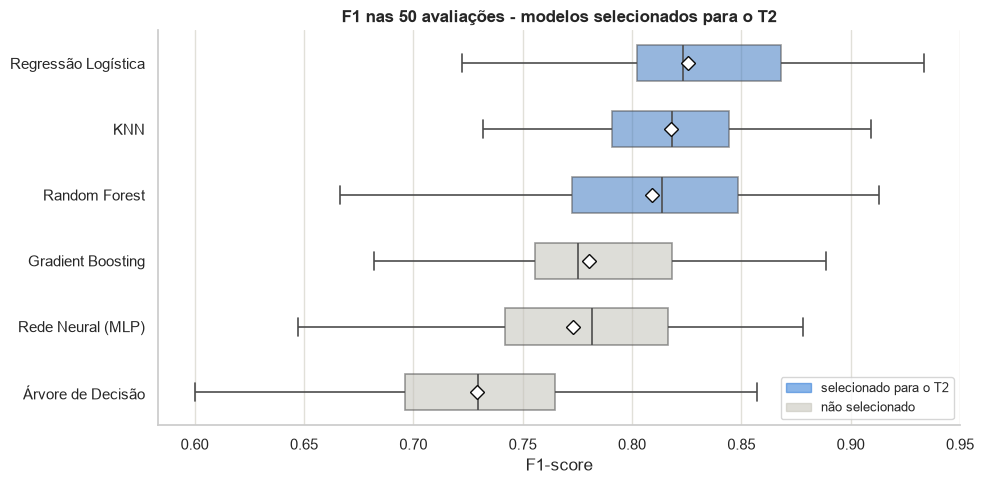

In [36]:
SELECIONADOS = ["Regressão Logística", "KNN", "Random Forest"]

suporte = pd.DataFrame({
    "Posição (F1)": [list(ordem).index(n) + 1 for n in ordem],
    "F1": media[METRICA_PRINCIPAL].loc[ordem].map("{:.3f}".format) + " ± " + desvio[METRICA_PRINCIPAL].loc[ordem].map("{:.3f}".format),
    "Recall": media["Recall"].loc[ordem].map("{:.3f}".format),
    "Precisão": media["Precisão"].loc[ordem].map("{:.3f}".format),
    "ROC-AUC": media["ROC-AUC"].loc[ordem].map("{:.3f}".format),
    "Diferença de F1 para o 1º": (media[METRICA_PRINCIPAL].max() - media[METRICA_PRINCIPAL].loc[ordem]).map("{:.3f}".format),
    "Selecionado": ["sim" if n in SELECIONADOS else "não" for n in ordem],
}, index=ordem)
display(suporte)

## F1 dos selecionados × demais (mesmo boxplot da Seção 8.2, com os selecionados destacados)
cores = {n: (COR_PRINCIPAL if n in SELECIONADOS else "#c3c2b7") for n in ordem}
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=resultados_longos, y="Algoritmo", x=METRICA_PRINCIPAL, order=ordem, hue="Algoritmo",
            palette=cores, legend=False, ax=ax, width=0.55, showfliers=False, linewidth=1.2, boxprops={"alpha": 0.55},
            showmeans=True, meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "#0b0b0b",
                                       "markersize": 7})
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=COR_PRINCIPAL, alpha=0.55, label="selecionado para o T2"),
                   Patch(color="#c3c2b7", alpha=0.55, label="não selecionado")], loc="lower right", fontsize=9)
ax.set_title("F1 nas 50 avaliações - modelos selecionados para o T2")
ax.set_xlabel("F1-score")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

### Justificativa da seleção

Selecionamos os modelos **Regressão Logística, KNN e Random Forest** para o T2, especialmente pelo fato de possuírem as três maiores médias de F1 no spot-checking, mas também porque representam modelos inerentemente interpretáveis (Regressão e KNN, apesar do KNN sofrer um pouco pelos dados possuírem alta dimensionalidade) ou derivado do ensemble de modelos inerentemente interpretáveis (Random Forest, apesar de não ser propriamente interpretável) - assim, entendemos que será mais fácil e intuitivo realizar o julgamento e tomada de decisões quando eventualmente precisarmos no segundo trabalho. Além disso, será especialmente interessante realizar a comparação entre um modelo "preguiçoso"/que não constrói um modelo no treinamento e possui 1 hiperparâmetro principal, um modelo linear único com poucos hiperparâmetros e um modelo que é um ensemble de vários outros modelos treinados (árvores) com muitos hiperparâmetros.